In [2]:
import pandas as pd
import numpy as np

# Exploratory data analysis 

In [3]:
# Load the Airbnb New York City 2019 dataset from the raw data folder
df = pd.read_csv(r'D:\Data Analysis\Airbnb data analysis project\Data_Files\Raw_Files\AB_NYC_2019.csv')

In [4]:
# Display the first 5 rows to verify successful loading and inspect columns
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [5]:
# Verify the total number of rows and columns in the raw dataset
print(f"Dataset Shape: {df.shape[0]:,} rows and {df.shape[1]} columns")

Dataset Shape: 48,895 rows and 16 columns


In [6]:
# Get a concise summary of the DataFrame including non-null counts and memory usage
df.info()
# make last_review date not object all other columns are correct 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [7]:
# Check the exact count of missing values per column
print("\nMissing Values Count per Column:")
print(df.isnull().sum())


Missing Values Count per Column:
id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64


In [8]:
# Generate summary statistics for numerical features to spot distributions, outliers, and extremes
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [9]:
df['price'].describe() # remove the rows contain price = 0 (has no logic)

count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64

In [10]:
df['room_type'].unique()

array(['Private room', 'Entire home/apt', 'Shared room'], dtype=object)

In [11]:
df['neighbourhood_group'].unique()

array(['Brooklyn', 'Manhattan', 'Queens', 'Staten Island', 'Bronx'],
      dtype=object)

In [12]:
# check if there is any duplicates
df.duplicated().sum()

np.int64(0)

# Data Cleaning and preprocessing 

In [13]:
# 1. Convert last_review to datetime and create a review presence flag
df['last_review'] = pd.to_datetime(df['last_review'])
df['has_reviews'] = df['last_review'].notnull().astype(int)


In [14]:
# 2. Fill missing reviews_per_month with 0 (no reviews = 0 review rate)
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

In [15]:
# 3. Fill missing names and host names with 'Unknown'
df['name'] = df['name'].fillna('Unknown')
df['host_name'] = df['host_name'].fillna('Unknown')

In [16]:
# 4. Convert categorical variables to 'category' dtype to optimize memory and performance
df['neighbourhood_group'] = df['neighbourhood_group'].astype('category')
df['room_type'] = df['room_type'].astype('category')

In [17]:
# Remove listings with price equal to 0 (invalid data) directly in-place
zero_price_indices = df[df['price'] == 0].index
removed_count = len(zero_price_indices)
df.drop(zero_price_indices, inplace=True)

print(f"Removed {removed_count} listings with a price of $0.")
print(f"Row count after removing invalid prices: {len(df):,}")

Removed 11 listings with a price of $0.
Row count after removing invalid prices: 48,884


In [18]:
# Inspect price percentiles to understand upper tail
print(df['price'].describe(percentiles=[0.90, 0.95, 0.99]))

# Flag extreme luxury prices (> $1,000) rather than deleting them
df['is_extreme_price'] = (df['price'] > 1000).astype(int)
print(f"Extreme price listings (> $1,000): {df['is_extreme_price'].sum():,}")

# Flag long-term stays (> 30 minimum nights)
df['is_long_term_stay'] = (df['minimum_nights'] > 30).astype(int)
print(f"Long-term stay listings (> 30 nights): {df['is_long_term_stay'].sum():,}")

count    48884.000000
mean       152.755053
std        240.170260
min         10.000000
50%        106.000000
90%        269.000000
95%        355.000000
99%        799.000000
max      10000.000000
Name: price, dtype: float64
Extreme price listings (> $1,000): 239
Long-term stay listings (> 30 nights): 747


In [19]:
# Drop text columns not needed for modeling/analysis (name and host_name)
df_modeling = df.drop(columns=['name', 'host_name'])

# Feature Engineering for Data Analysis 

In [20]:
# 1. Price Category using intuitive fixed bins
# Budget: <= $100, Mid: $101 - $200, Premium: $201 - $500, Luxury: > $500
price_bins = [-np.inf, 100, 200, 500, np.inf]
price_labels = ['Budget', 'Mid', 'Premium', 'Luxury']
df['price_category'] = pd.cut(df['price'], bins=price_bins, labels=price_labels)


print(df['price_category'].value_counts())

price_category
Budget     23917
Mid        16583
Premium     7340
Luxury      1044
Name: count, dtype: int64


In [21]:
# 2. Stay Type based on minimum nights
# Short: <= 7 nights, Medium: 8 to 30 nights, Long-term: > 30 nights
def get_stay_type(mins):
    if mins <= 7:
        return 'Short'
    elif mins <= 30:
        return 'Medium'
    else:
        return 'Long-term'

df['stay_type'] = df['minimum_nights'].apply(get_stay_type)



print(df['stay_type'].value_counts())

stay_type
Short        41553
Medium        6584
Long-term      747
Name: count, dtype: int64


In [22]:
# 3. Availability Category based on availability_365
def get_availability_category(days):
    if days == 0:
        v = 'Not Available'
    elif days <= 90:
        v = 'Low'
    elif days <= 180:
        v = 'Medium'
    else:
        v = 'High'
    return v

df['availability_category'] = df['availability_365'].apply(get_availability_category)


print(df['availability_category'].value_counts())

availability_category
Not Available    17530
High             14361
Low              11711
Medium            5282
Name: count, dtype: int64


In [23]:
df['room_type'].unique()

['Private room', 'Entire home/apt', 'Shared room']
Categories (3, object): ['Entire home/apt', 'Private room', 'Shared room']

# Data Analysis and insights


# 1- What is the mix of room types across NYC?
Entire homes/apartments make up the majority of listings ($52.0\%$), closely followed by private rooms ($45.7\%$), while shared rooms are a tiny niche ($2.4\%$). Manhattan and Brooklyn account for the vast majority of entire home and private room listings.

In [24]:
# Section A: Room Type Counts and Percentages
room_counts = df['room_type'].value_counts()
room_pct = df['room_type'].value_counts(normalize=True) * 100

print("Room Type Distribution:")
for rt, count, pct in zip(room_counts.index, room_counts.values, room_pct.values):
    print(f"  - {rt}: {count:,} listings ({pct:.1f}%)")

# Cross-tabulation between Borough and Room Type
crosstab_room_borough = pd.crosstab(df['neighbourhood_group'], df['room_type'], margins=True)
print("\nBorough x Room Type Cross-Tabulation:")
print(crosstab_room_borough)

Room Type Distribution:
  - Entire home/apt: 25,407 listings (52.0%)
  - Private room: 22,319 listings (45.7%)
  - Shared room: 1,158 listings (2.4%)

Borough x Room Type Cross-Tabulation:
room_type            Entire home/apt  Private room  Shared room    All
neighbourhood_group                                                   
Bronx                            379           651           60   1090
Brooklyn                        9558         10126          411  20095
Manhattan                      13198          7982          480  21660
Queens                          2096          3372          198   5666
Staten Island                    176           188            9    373
All                            25407         22319         1158  48884


# Which boroughs and neighbourhoods have the most listings and review activity?
Manhattan ($21,660$ listings) and Brooklyn ($20,095$ listings) dominate the NYC Airbnb market, together representing over $85\%$ of all listings. Queens is a distant third ($5,666$), while the Bronx and Staten Island have minimal supply. Williamsburg, Bedford-Stuyvesant, and Harlem lead individual neighbourhoods.

In [25]:
# Section B: Listings and Review Activity by Area
listings_by_borough = df['neighbourhood_group'].value_counts()
top_neighbourhoods = df['neighbourhood'].value_counts().head(10)

print("Listings by Borough:")
print(listings_by_borough)

print("\nTop 10 Neighbourhoods by Listing Volume:")
print(top_neighbourhoods)

Listings by Borough:
neighbourhood_group
Manhattan        21660
Brooklyn         20095
Queens            5666
Bronx             1090
Staten Island      373
Name: count, dtype: int64

Top 10 Neighbourhoods by Listing Volume:
neighbourhood
Williamsburg          3919
Bedford-Stuyvesant    3710
Harlem                2658
Bushwick              2462
Upper West Side       1971
Hell's Kitchen        1958
East Village          1853
Upper East Side       1798
Crown Heights         1564
Midtown               1545
Name: count, dtype: int64


# How do nightly prices differ by borough, room type, and neighbourhood?
Manhattan is significantly more expensive with a median price of $\$150$, compared to Brooklyn ($\$90$), Queens ($\$75$), Staten Island ($\$75$), and the Bronx ($\$65$). Entire homes command a median price of $\$160$, versus $\$70$ for private rooms and $\$45$ for shared rooms. Tribeca ($\$295$) and NoHo ($\$250$) lead as the most expensive neighbourhoods.

In [26]:
# Section C: Median Prices by Borough and Room Type
median_price_borough = df.groupby('neighbourhood_group')['price'].median()
median_price_room = df.groupby('room_type')['price'].median()

print("Median Price by Borough ($):")
print(median_price_borough)

print("\nMedian Price by Room Type ($):")
print(median_price_room)

# Top 10 most expensive neighbourhoods (filtering for at least 30 listings)
nh_counts = df['neighbourhood'].value_counts()
valid_nh = nh_counts[nh_counts >= 30].index
expensive_nh = df[df['neighbourhood'].isin(valid_nh)].groupby('neighbourhood')['price'].median().sort_values(ascending=False).head(10)
print("\nTop 10 Most Expensive Neighbourhoods (min 30 listings):")
print(expensive_nh)

Median Price by Borough ($):
neighbourhood_group
Bronx             65.0
Brooklyn          90.0
Manhattan        150.0
Queens            75.0
Staten Island     75.0
Name: price, dtype: float64

Median Price by Room Type ($):
room_type
Entire home/apt    160.0
Private room        70.0
Shared room         45.0
Name: price, dtype: float64

Top 10 Most Expensive Neighbourhoods (min 30 listings):
neighbourhood
Tribeca               295.0
NoHo                  250.0
Flatiron District     225.0
Midtown               210.0
West Village          200.0
Financial District    200.0
SoHo                  199.0
Chelsea               199.0
Greenwich Village     197.5
Battery Park City     195.0
Name: price, dtype: float64


C:\Users\Mega Store\AppData\Local\Temp\ipykernel_17016\2290817773.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  median_price_borough = df.groupby('neighbourhood_group')['price'].median()
C:\Users\Mega Store\AppData\Local\Temp\ipykernel_17016\2290817773.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  median_price_room = df.groupby('room_type')['price'].median()


# Which listings or areas perform best by review activity?
Outer borough neighborhoods with lower median prices often exhibit high review velocity, indicating strong guest demand and high turnover rates.

In [27]:
# Section F: Top Neighbourhoods by Average Reviews per Month
top_review_nh = df.groupby('neighbourhood')['reviews_per_month'].mean().sort_values(ascending=False).head(10)
print("Top Neighbourhoods by Average Reviews per Month:")
print(top_review_nh)

Top Neighbourhoods by Average Reviews per Month:
neighbourhood
East Elmhurst          4.458000
Silver Lake            4.340000
Springfield Gardens    4.193176
Rosebank               3.812857
Huguenot               3.760000
Schuylerville          3.157692
South Ozone Park       3.019750
Jamaica Hills          2.901250
Queens Village         2.684000
Fresh Meadows          2.646875
Name: reviews_per_month, dtype: float64


In [28]:
# save the cleaned data for dashboard 
df.to_csv(r'D:\Data Analysis\Airbnb data analysis project\Data_Files\Cleaned_Files\cleaned_airbnb_data.csv')

# Visulizations

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set consistent style and color palette
sns.set_theme(style="whitegrid")
palette = sns.color_palette("muted")

C:\Users\Mega Store\AppData\Local\Temp\ipykernel_17016\940610089.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='room_type', order=df['room_type'].value_counts().index, palette=palette)
C:\Users\Mega Store\AppData\Local\Temp\ipykernel_17016\940610089.py:3: UserWarning: The palette list has more values (10) than needed (3), which may not be intended.
  ax = sns.countplot(data=df, x='room_type', order=df['room_type'].value_counts().index, palette=palette)


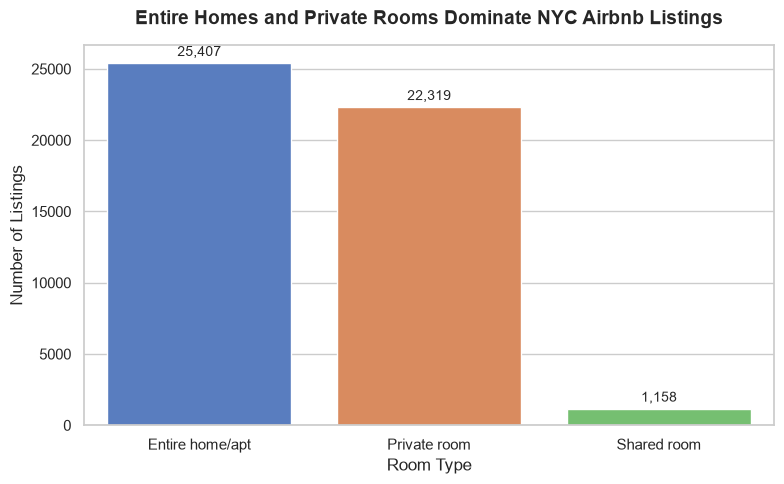

In [30]:
# 1- Room Types
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='room_type', order=df['room_type'].value_counts().index, palette=palette)
plt.title('Entire Homes and Private Rooms Dominate NYC Airbnb Listings', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Room Type', fontsize=12)
plt.ylabel('Number of Listings', fontsize=12)

# Add data value labels on top of each bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

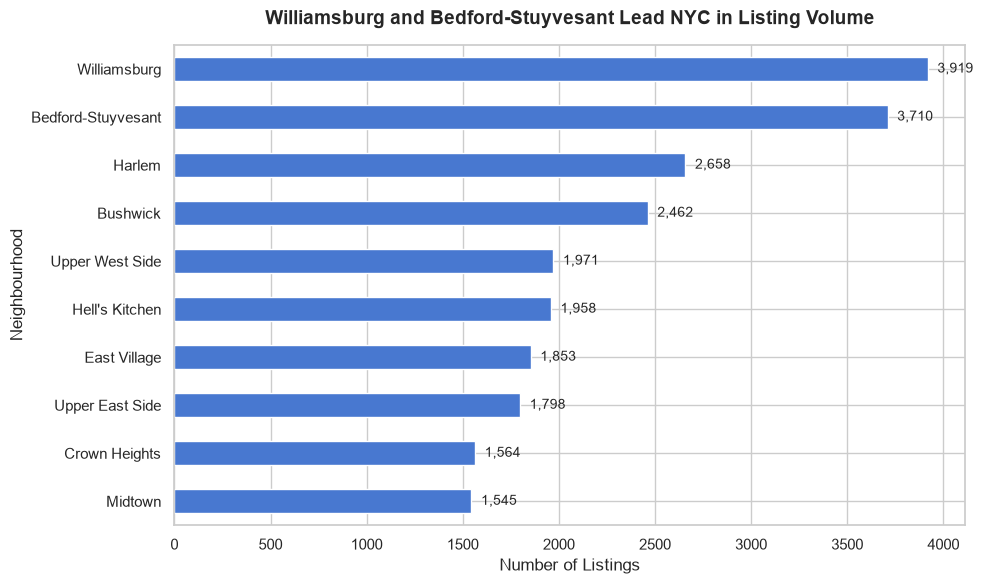

In [31]:
# 2- Top Neighbourhoods
plt.figure(figsize=(10, 6))
top_nh = df['neighbourhood'].value_counts().head(10).sort_values()
ax = top_nh.plot(kind='barh', color=palette[0])
plt.title('Williamsburg and Bedford-Stuyvesant Lead NYC in Listing Volume', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Number of Listings', fontsize=12)
plt.ylabel('Neighbourhood', fontsize=12)

for index, value in enumerate(top_nh):
    ax.text(value + 50, index, f'{value:,}', va='center', fontsize=10)

plt.tight_layout()
plt.savefig('../images/top_neighbourhoods.png', dpi=300)
plt.show()

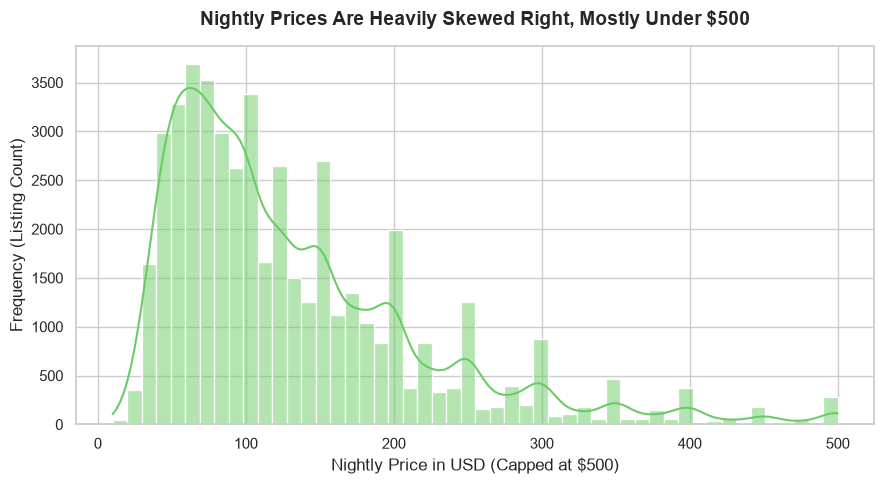

In [32]:
# 3- Price Distribution 
plt.figure(figsize=(9, 5))
capped_prices = df[df['price'] <= 500]['price']
sns.histplot(capped_prices, bins=50, kde=True, color=palette[2])
plt.title('Nightly Prices Are Heavily Skewed Right, Mostly Under $500', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Nightly Price in USD (Capped at $500)', fontsize=12)
plt.ylabel('Frequency (Listing Count)', fontsize=12)
plt.tight_layout()
plt.savefig('../images/price_distribution.png', dpi=300)
plt.show()


C:\Users\Mega Store\AppData\Local\Temp\ipykernel_17016\50986242.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df[df['price'] <= 1000], x='neighbourhood_group', y='price', palette='muted')


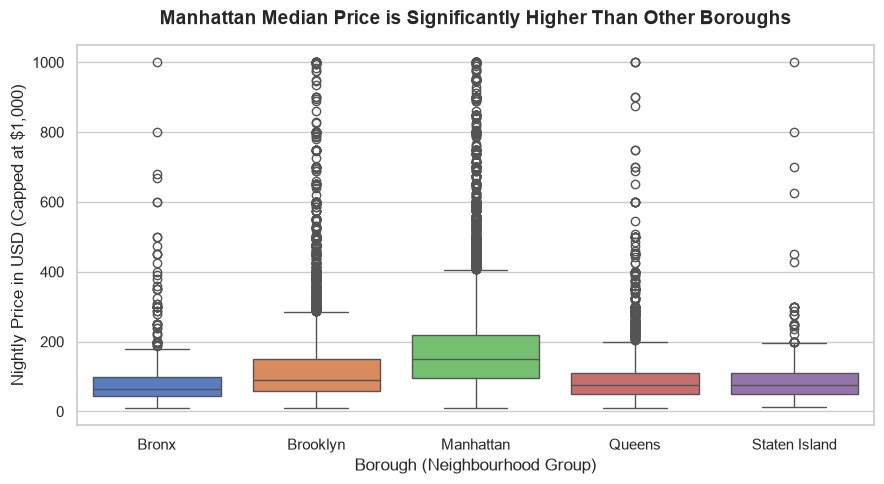

In [33]:
# 4- Price by Borough
plt.figure(figsize=(9, 5))
sns.boxplot(data=df[df['price'] <= 1000], x='neighbourhood_group', y='price', palette='muted')
plt.title('Manhattan Median Price is Significantly Higher Than Other Boroughs', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Borough (Neighbourhood Group)', fontsize=12)
plt.ylabel('Nightly Price in USD (Capped at $1,000)', fontsize=12)
plt.tight_layout()
plt.savefig('../images/price_by_borough_boxplot.png', dpi=300)
plt.show()